# 01 - Data acquisition, cleaning and EDA
**Dataset:** UCI Heart Disease (id 45), Cleveland Clinic subset - 303 patients, 13 clinical attributes, target `num` (0 = <50% vessel narrowing, 1-4 = >50%).

The logic lives in `src/heartrisk/data.py` and `src/heartrisk/eda.py`; this notebook runs it and records the findings that drove modelling decisions.

In [1]:
import json, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
from heartrisk import config

## 1. Acquisition
`python -m heartrisk.data download` tries the UCI archive first, then byte-identical mirrors whose SHA-256 must match a pinned hash. Provenance is written next to the raw files.

In [2]:
from heartrisk import data
prov_path = config.RAW_DIR / "provenance.json"
if not (config.RAW_DIR / "processed.cleveland.data").exists():
    data.download()
prov = json.loads(prov_path.read_text())
pd.DataFrame(prov["files"]).T[["source", "sha256", "url"]]

,source,sha256,url
cleveland,mirror,a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f...,https://raw.githubusercontent.com/reinaldoq/pr...
hungarian,weka-arff,5d90c99b417dedec985b9a90df7d2f01ec1c49dea418fa...,https://raw.githubusercontent.com/renatopp/arf...


## 2. Raw data quality

In [3]:
raw = data.load_raw("cleveland")
print(raw.shape)
display(raw.head())
print("Missing values per column:"); print(raw.isna().sum()[lambda s: s > 0])
print("Exact duplicate rows:", raw.duplicated().sum())
print("Severity distribution (num):", raw["num"].value_counts().sort_index().to_dict())

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Missing values per column:
ca      4
thal    2
dtype: int64
Exact duplicate rows: 0
Severity distribution (num): {0: 164, 1: 55, 2: 36, 3: 35, 4: 13}


## 3. Cleaning
* `?` markers -> NaN (4 in `ca`, 2 in `thal`). **Not dropped**: imputation happens *inside* the model pipeline, fitted on training folds only, so the same logic serves missing values at inference.
* Values outside physiological ranges -> NaN (none in Cleveland; e.g. `chol = 0` in the Hungarian file).
* Target binarised: `num > 0` -> 1 (presence of disease).
* Nullable integer types for categorical codes.

In [4]:
clean, report = data.clean(raw)
data.validate(clean)
print(json.dumps(report.to_dict(), indent=2))
clean.describe().T.round(2)

{
  "rows_in": 303,
  "rows_out": 303,
  "duplicates_removed": 0,
  "out_of_range_nulled": {},
  "missing_after": {
    "ca": 4,
    "thal": 2
  },
  "positive_rate": 0.4587
}


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 4. Exploratory analysis

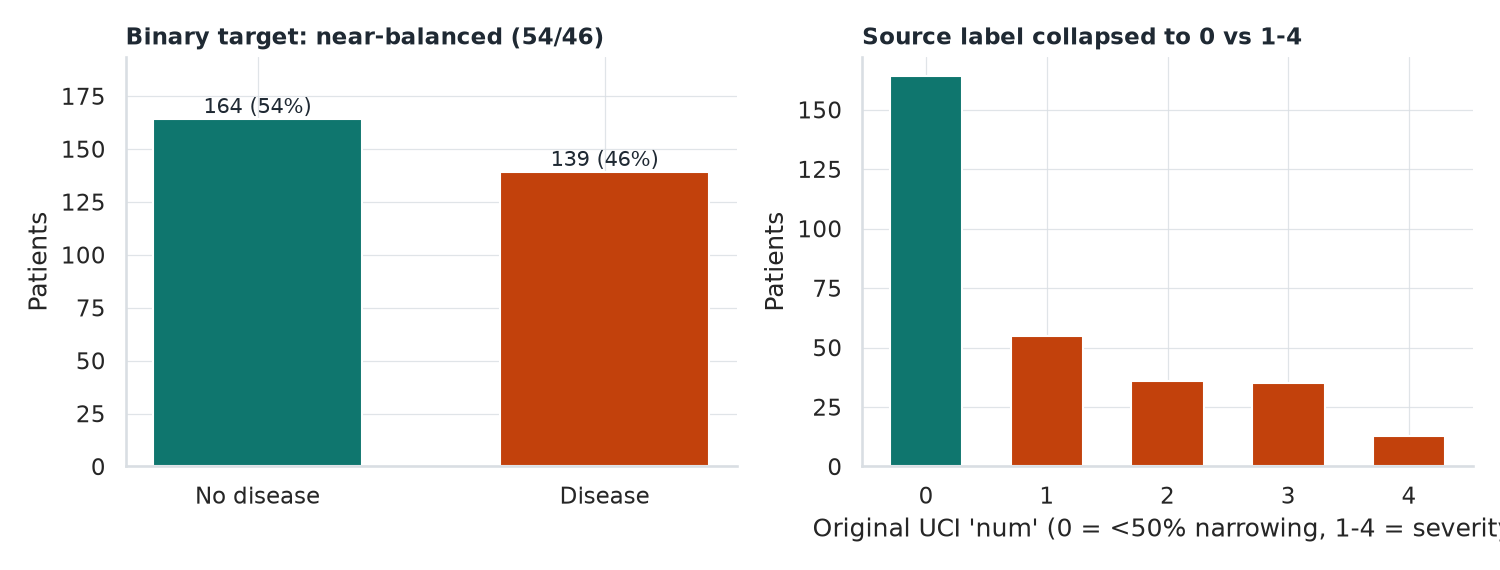

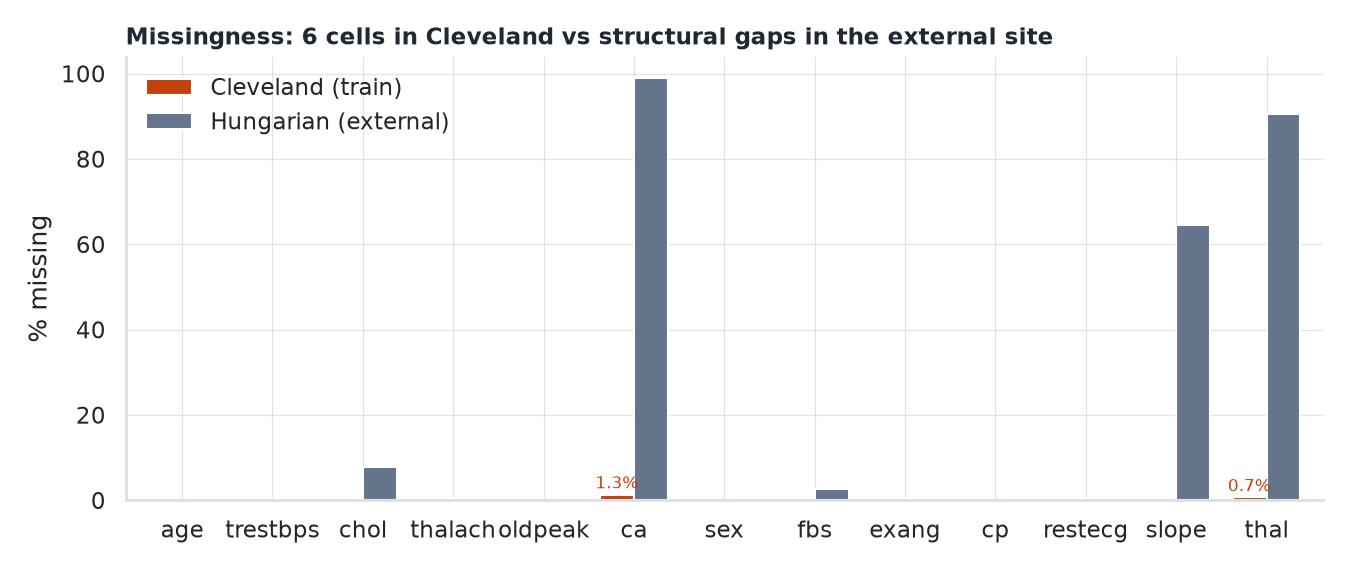

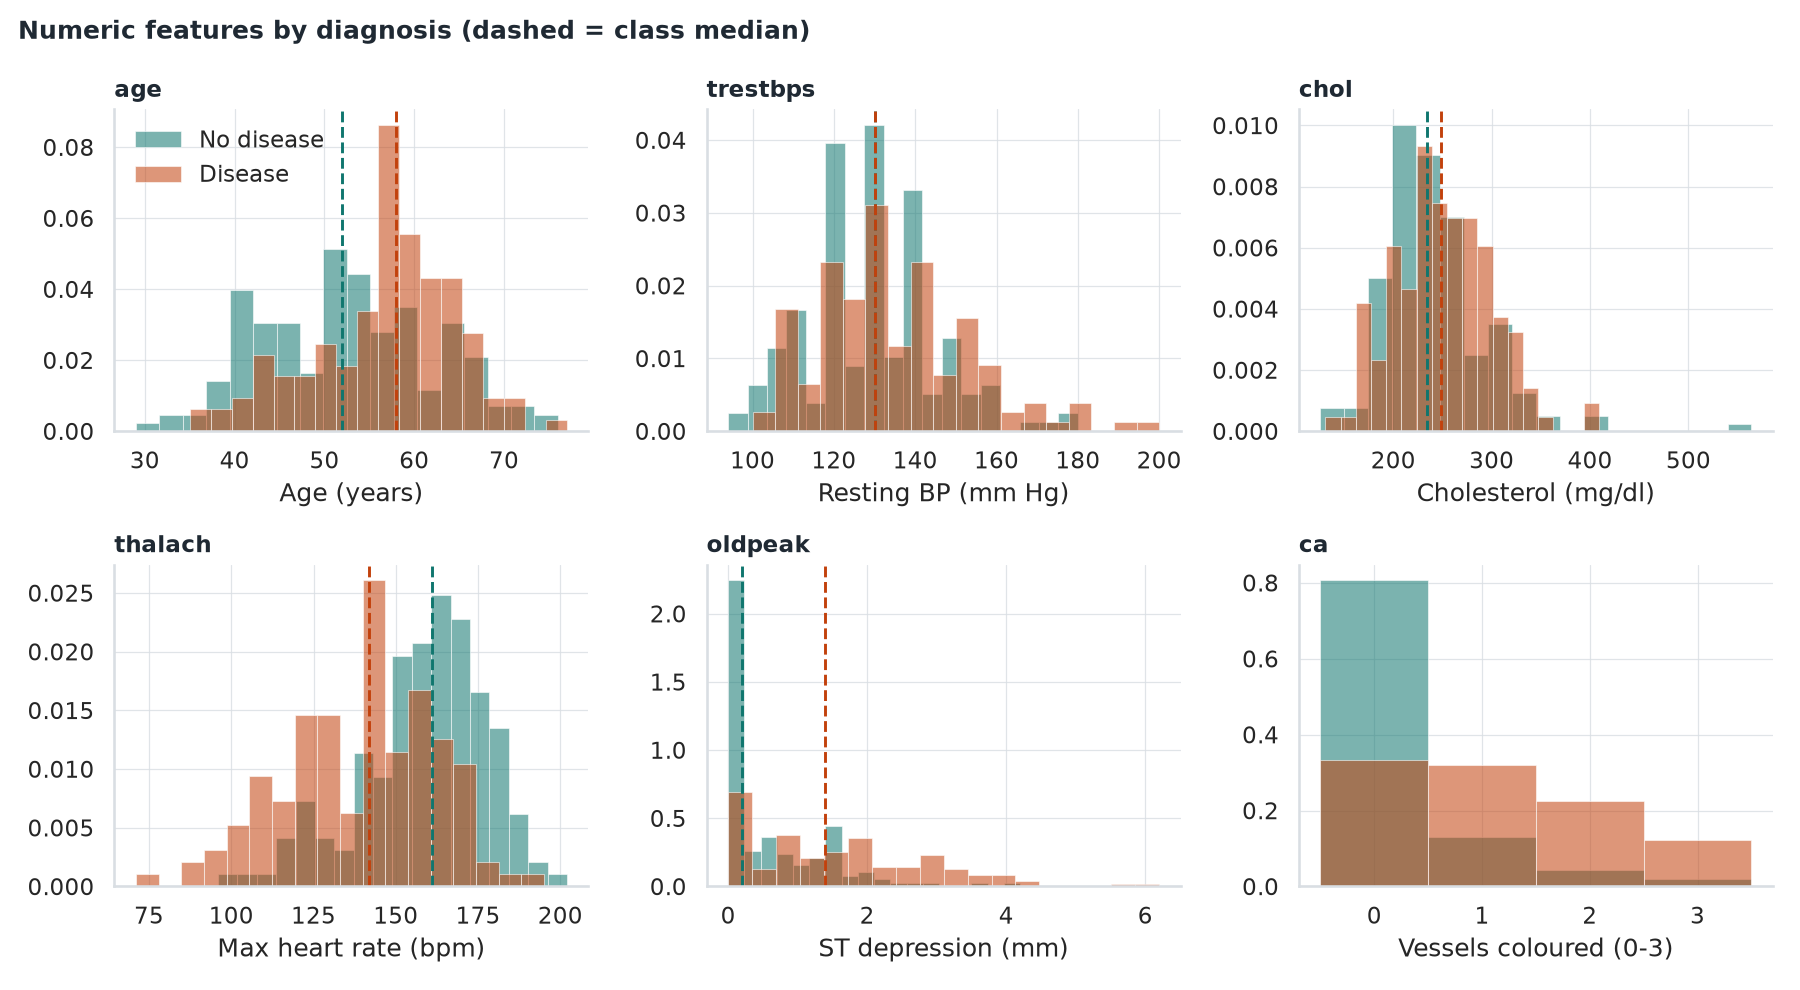

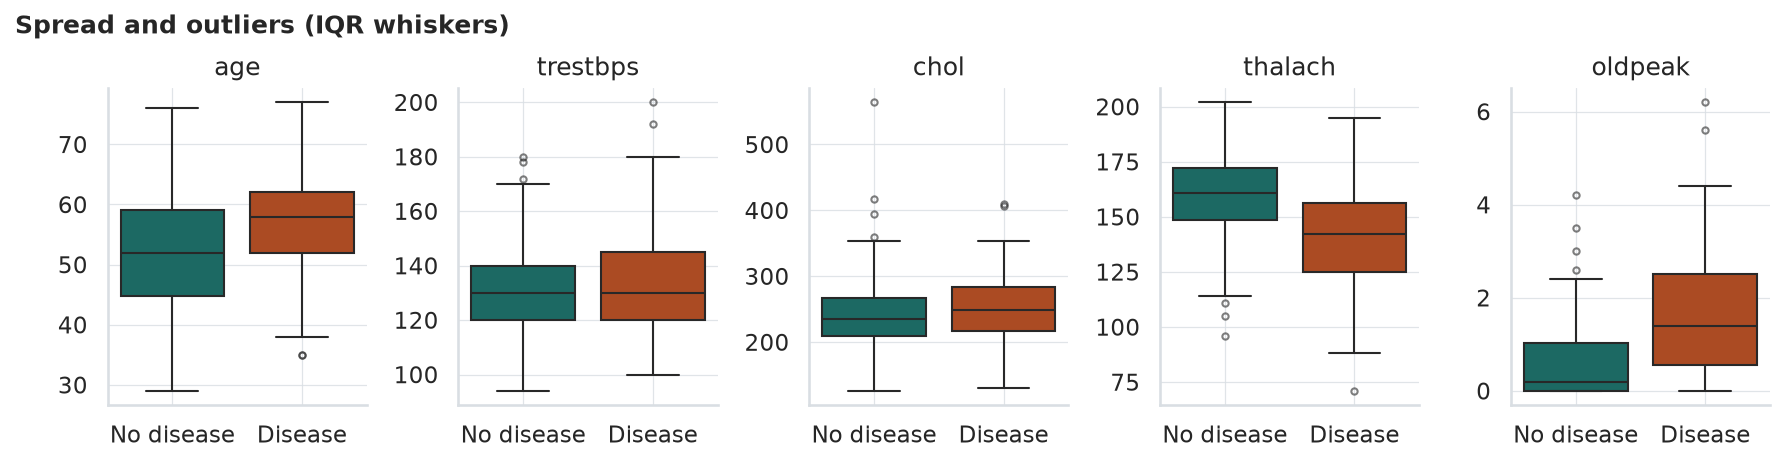

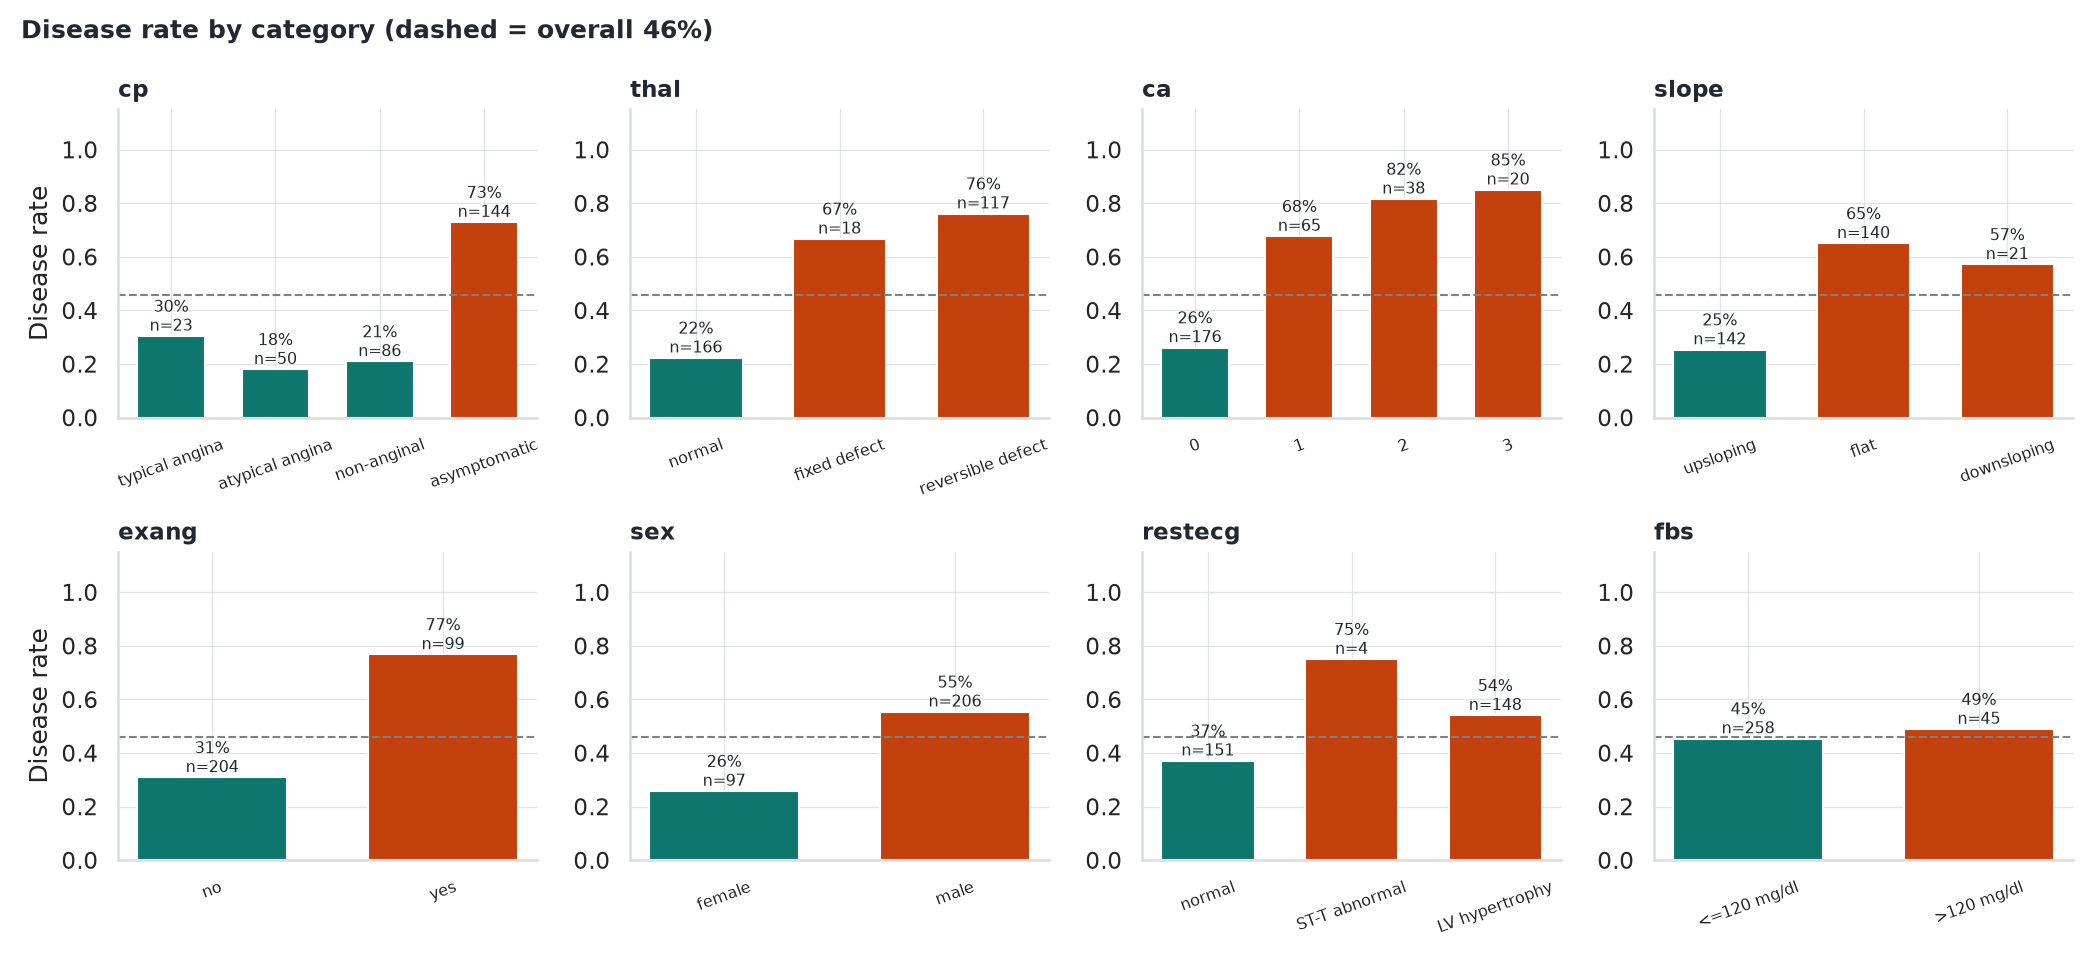

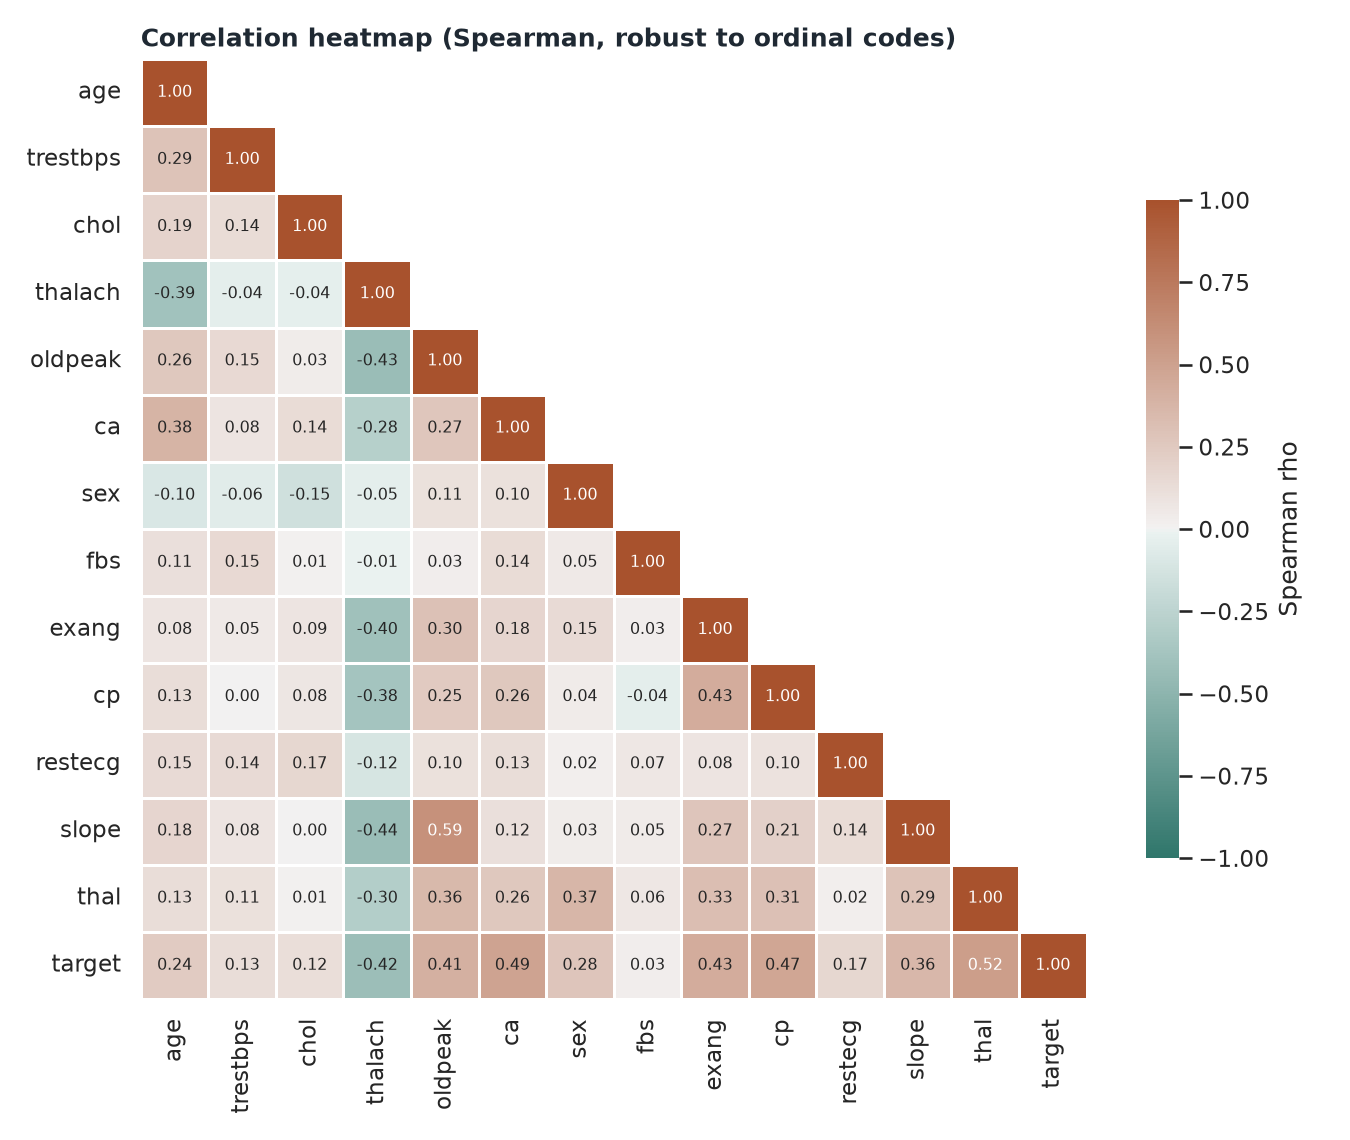

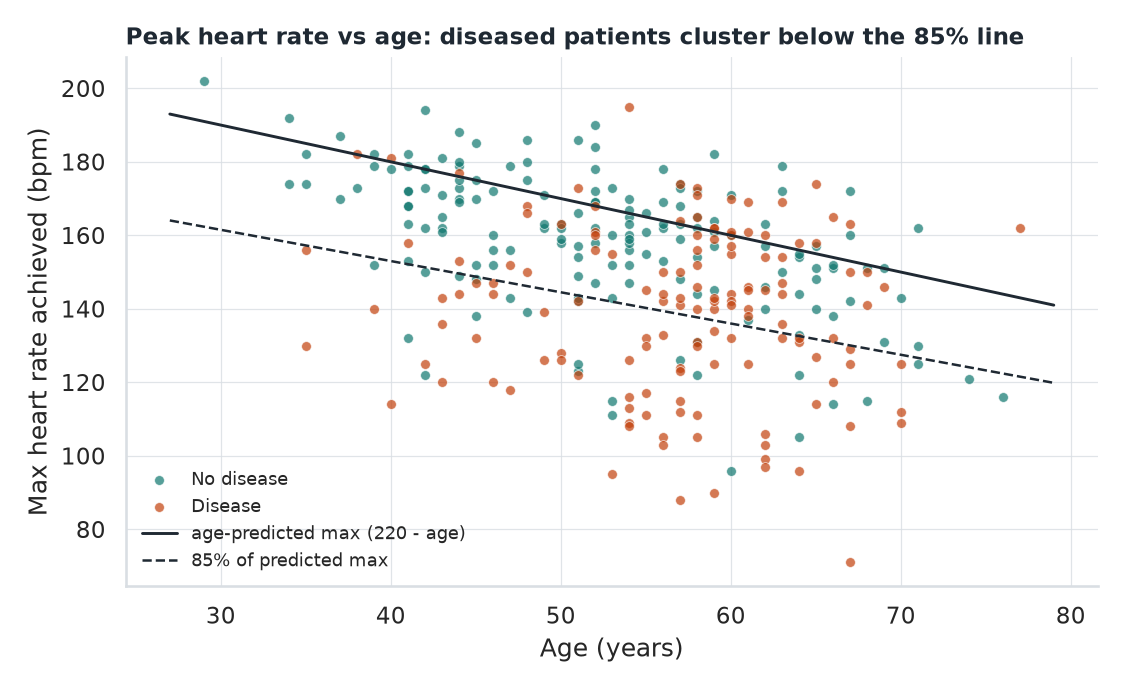

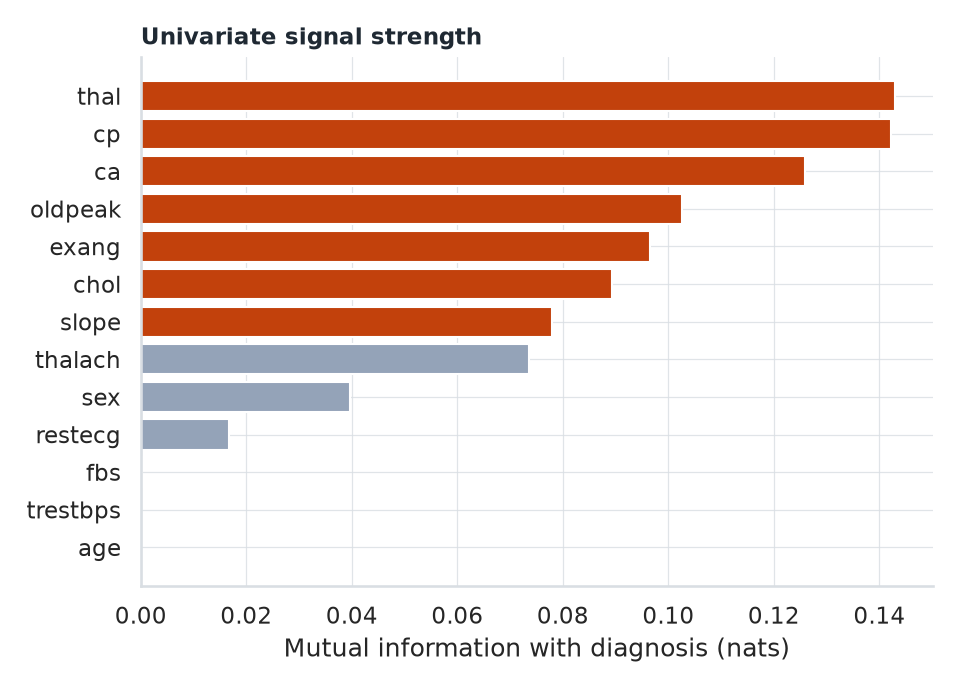

In [5]:
from heartrisk import eda
summary = eda.run()
for fig in summary["figures"]:
    display(Image(filename=str(config.PROJECT_ROOT / fig), width=820))

## 5. Key numbers

In [6]:
pd.DataFrame({
    "spearman_with_target": summary["spearman_with_target"],
    "mutual_information": summary["mutual_information"],
}).sort_values("spearman_with_target", key=abs, ascending=False).round(3)

,spearman_with_target,mutual_information
thal,0.522,0.143
ca,0.489,0.126
cp,0.472,0.142
exang,0.432,0.096
thalach,-0.423,0.074
oldpeak,0.413,0.103
slope,0.364,0.078
sex,0.277,0.040
age,0.237,0.000
restecg,0.169,0.017


In [7]:
eda.outlier_table(clean).round(1)

,feature,min,q1,median,q3,max,iqr_outliers
0,age,29.0,48.0,56.0,61.0,77.0,0
1,trestbps,94.0,120.0,130.0,140.0,200.0,9
2,chol,126.0,211.0,241.0,275.0,564.0,5
3,thalach,71.0,133.5,153.0,166.0,202.0,1
4,oldpeak,0.0,0.0,0.8,1.6,6.2,5
5,ca,0.0,0.0,0.0,1.0,3.0,20


## 6. Findings that shape the modelling
1. **Near-balanced target (164 vs 139)** - accuracy is meaningful, but ROC-AUC is used for model ranking because it is threshold-free; recall is reported because a missed diagnosis is the costly error.
2. **Strongest signals are categorical** (`thal`, `cp`, `ca`, `exang`) - they are one-hot encoded rather than treated as ordinal numbers.
3. **Asymptomatic chest pain (cp = 4) carries 73% disease prevalence** versus 18-30% for anginal types: counter-intuitive but well documented for this cohort; a model must not assume monotonic ordering of `cp`.
4. **Age-adjusted peak heart rate**: patients reaching < 85% of the age-predicted maximum have 72% disease prevalence vs 35% above. This motivates the engineered feature `hr_pct_predicted`, tested as an ablation in the grid search.
5. **Outliers** (`trestbps`, `chol`, `oldpeak`) are clinically plausible extremes, not errors - kept, and handled by robust/regularised models rather than clipping.
6. **External site (Hungarian)** has structural missingness (`ca` 99%, `thal` 90%) - a realistic data-shift scenario used for external validation.